# Time Integrators: BDF1, Crank-Nicolson, BDF2 and TR-BDF2

ANTS has four implicit time integrators, selected with
`TimeDependentData(time_disc=...)`:

| `TemporalDiscretization` | Order | Initial flux | Entries for a time-varying external source |
|---|---|---|---|
| `BDF1` (default) | 1 | cell centres, `(cells, angles, groups)` | `steps`, at `edges_t[1:]` |
| `CN` | 2 | cell edges, `(cells + 1, angles, groups)` | `steps + 1`, at `edges_t` |
| `BDF2` | 2 | cell centres, `(cells, angles, groups)` | `steps`, at `edges_t[1:]` |
| `TR_BDF2` | 2 | cell edges, `(cells + 1, angles, groups)` | `2 * steps + 1`, at `ants.gamma_time_steps(edges_t)` |

A time-varying boundary source has no entry at $t = 0$: it needs `steps`
entries at `edges_t[1:]`, or `2 * steps` for TR-BDF2. A source that is
constant in time needs only one entry for every integrator
(`ants.external1d.time_dependence_constant`). The initial flux is always passed
as `SourceData(initial_flux=...)` in 1D. See
[Time-Dependent Problems](../time-dependent-inputs.rst) for the other inputs.

This notebook measures the order of accuracy of each integrator, then runs a
stiff transient (Reed's problem) with a large time step to show how they
behave when accuracy and stability pull apart. It finishes with the
scattering reaction rate over time.

In [1]:
import os
import tempfile

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import NullFormatter

import ants
from ants.datatypes import (
    GeometryData,
    MaterialData,
    SolverData,
    SourceData,
    TemporalDiscretization,
    TimeDependentData,
)
from ants.timed1d import time_dependent
from ants.utils import manufactured_1d as mms

# Plot colors: one per method, plus a neutral dashed reference
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
REFERENCE = dict(color="#52514e", ls="--", lw=2)


def tidy(ax):
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

## Order of accuracy

The manufactured solution $\psi(x, \mu, t) = 1 + \sin(x - t/2) + \cos\mu$ on
$x \in [0, \pi]$ is smooth in time. The run goes to $t = 1$ with a 1600-cell
mesh so the spatial error stays below the time error. The function below
builds the inputs each integrator expects; the initial flux location and the
number of source entries are the parts that differ.

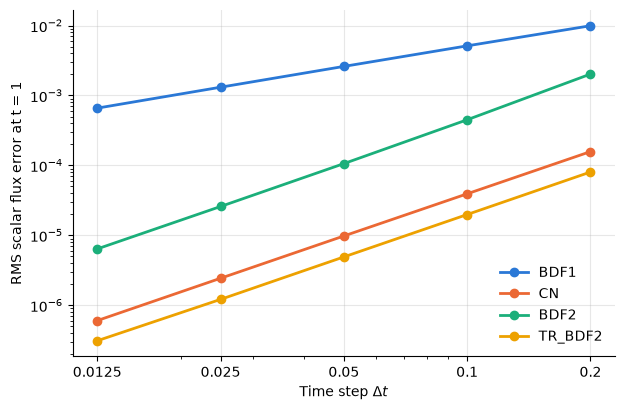

BDF1     observed order: [0.96 0.98 0.99 0.99]
CN       observed order: [2.   2.   2.01 2.01]
BDF2     observed order: [2.17 2.08 2.04 2.01]
TR_BDF2  observed order: [2.02 2.01 2.02 1.97]


In [2]:
cells = 1600
edges_x = np.linspace(0.0, np.pi, cells + 1)
centers_x = 0.5 * (edges_x[1:] + edges_x[:-1])
quadrature = ants.angular_x(8)
mu = quadrature.angle_x

mms_materials = MaterialData(
    total=np.array([[1.0]]),
    scatter=np.array([[[0.0]]]),
    fission=np.array([[[0.0]]]),
    velocity=np.ones(1),
)
mms_geometry = GeometryData(
    medium_map=np.zeros(cells, dtype=np.int32), delta_x=np.diff(edges_x)
)


def mms_sources(time_disc, edges_t):
    t0 = np.array([0.0])
    if time_disc in (TemporalDiscretization.BDF1, TemporalDiscretization.BDF2):
        initial = mms.solution_td_02(centers_x, mu, t0)[0]
        external = ants.external1d.manufactured_td_02(centers_x, mu, edges_t)[1:]
        boundary = ants.boundary1d.manufactured_td_02(mu, edges_t)[1:]
    elif time_disc == TemporalDiscretization.CN:
        initial = mms.solution_td_02(edges_x, mu, t0)[0]
        external = ants.external1d.manufactured_td_02(centers_x, mu, edges_t)
        boundary = ants.boundary1d.manufactured_td_02(mu, edges_t)[1:]
    else:  # TR-BDF2 also needs the intermediate (gamma) stage times
        gamma_t = ants.gamma_time_steps(edges_t)
        initial = mms.solution_td_02(edges_x, mu, t0)[0]
        external = ants.external1d.manufactured_td_02(centers_x, mu, gamma_t)
        boundary = ants.boundary1d.manufactured_td_02(mu, gamma_t)[1:]
    return SourceData(initial_flux=initial, external=external, boundary_x=boundary)


def mms_error(time_disc, steps, final_time=1.0):
    edges_t = np.linspace(0.0, final_time, steps + 1)
    time_data = TimeDependentData(
        steps=steps, dt=final_time / steps, time_disc=time_disc
    )
    flux = time_dependent(
        mms_materials,
        mms_sources(time_disc, edges_t),
        mms_geometry,
        quadrature,
        SolverData(),
        time_data,
    )
    exact = mms.solution_td_02(centers_x, mu, np.array([final_time]))[0, :, :, 0]
    return np.sqrt(np.mean((flux[:, 0] - exact @ quadrature.angle_w) ** 2))


step_counts = np.array([5, 10, 20, 40, 80])
errors = {
    disc: np.array([mms_error(disc, steps) for steps in step_counts])
    for disc in TemporalDiscretization
}

fig, ax = plt.subplots(figsize=(7, 4.5))
for color, (disc, error) in zip(COLORS, errors.items()):
    ax.loglog(1.0 / step_counts, error, color=color, lw=2, marker="o", ms=6,
              label=disc.name)
ax.set_xticks(1.0 / step_counts)
ax.set_xticklabels([f"{1 / n:g}" for n in step_counts])
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_xlabel("Time step $\\Delta t$")
ax.set_ylabel("RMS scalar flux error at t = 1")
ax.legend(frameon=False)
tidy(ax)
plt.show()

for disc, error in errors.items():
    order = np.log2(error[:-1] / error[1:])
    print(f"{disc.name:8s} observed order: {np.round(order, 2)}")

BDF1 is first order; CN, BDF2 and TR-BDF2 are all second order, so their
error drops by a factor of 4 each time $\Delta t$ is halved. On this smooth
problem, TR-BDF2 has the smallest error at every step size, about half that
of CN, and BDF2's error is roughly 10 times larger than CN's.

## A stiff transient: Reed's problem

Reed's problem is a 16 cm slab with vacuum boundaries and five regions,
symmetric about $x = 8$ cm:

| Region | Location (cm) | $\sigma_t$ | $\sigma_s$ | Source |
|---|---|---|---|---|
| Scatterer | 0-4, 12-16 | 1 | 0.9 | 1 in 2-4 and 12-14, otherwise 0 |
| Void | 4-5, 11-12 | 0 | 0 | 0 |
| Absorber | 5-6, 10-11 | 5 | 0 | 0 |
| Source | 6-10 | 50 | 0 | 50 |

The thin void, the thick absorber and the very thick source region make it a
standard stress test for transport discretizations.

The source switches on at $t = 0$ with zero initial flux and $v = 1$. With a
time step of $\Delta t = 1$, the source region has $v \sigma_t \Delta t = 50$,
so it is very stiff: the flux there reaches equilibrium almost immediately,
while the scattering regions take several mean free times to fill in.

Each run writes the flux at every step to a file with
`TimeDependentData(save_to_file=...)`, so the history can be plotted. The
reference uses BDF2 with $\Delta t = 0.01$.

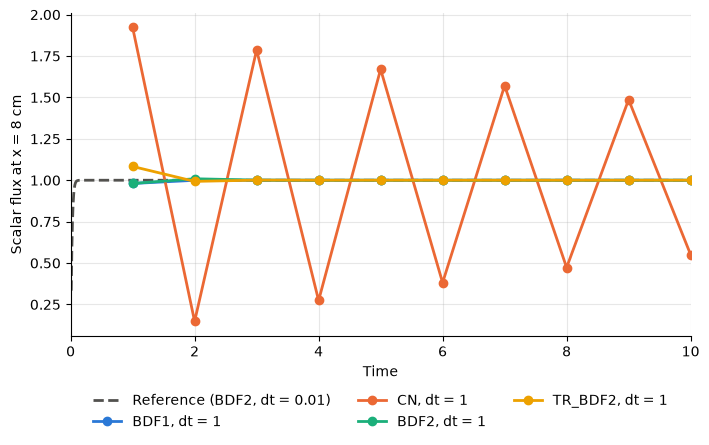

In [3]:
cells, angles = 320, 8
edges_x = np.linspace(0.0, 16.0, cells + 1)
centers_x = 0.5 * (edges_x[1:] + edges_x[:-1])
layers = [
    [0, "scatterer", "0-4, 12-16"],
    [1, "void", "4-5, 11-12"],
    [2, "absorber", "5-6, 10-11"],
    [3, "source", "6-10"],
]
medium_map = ants.spatial1d(layers, edges_x)
reed_materials = MaterialData(
    total=np.array([[1.0], [0.0], [5.0], [50.0]]),
    scatter=np.array([[[0.9]], [[0.0]], [[0.0]], [[0.0]]]),
    fission=np.zeros((4, 1, 1)),
    velocity=np.ones(1),
)
reed_geometry = GeometryData(
    medium_map=medium_map, delta_x=np.diff(edges_x), bc_x=[0, 0], geometry=1
)
reed_quadrature = ants.angular_x(angles)
# Constant source: one time entry works for every integrator
external = ants.external1d.time_dependence_constant(
    ants.external1d.reeds(edges_x, [0, 0])
)
workdir = tempfile.mkdtemp()


def run_reed(time_disc, dt, final_time=10.0):
    steps = round(final_time / dt)
    edge_based = time_disc in (TemporalDiscretization.CN, TemporalDiscretization.TR_BDF2)
    initial = np.zeros((cells + 1 if edge_based else cells, angles, 1))
    sources = SourceData(
        initial_flux=initial, external=external, boundary_x=np.zeros((1, 2, 1, 1))
    )
    path = os.path.join(workdir, f"{time_disc.name}_{steps}.npy")
    time_data = TimeDependentData(
        steps=steps, dt=dt, time_disc=time_disc, save_to_file=path
    )
    time_dependent(
        reed_materials, sources, reed_geometry, reed_quadrature, SolverData(), time_data
    )
    times = dt * np.arange(1, steps + 1)
    return times, np.load(path)  # flux history: (steps, cells, groups)


reference = run_reed(TemporalDiscretization.BDF2, dt=0.01)
coarse = {disc: run_reed(disc, dt=1.0) for disc in TemporalDiscretization}

middle = cells // 2  # x = 8 cm, the centre of the source region
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(reference[0], reference[1][:, middle, 0], label="Reference (BDF2, dt = 0.01)",
        **REFERENCE)
for color, (disc, (times, flux)) in zip(COLORS, coarse.items()):
    ax.plot(times, flux[:, middle, 0], color=color, lw=2, marker="o", ms=6,
            label=f"{disc.name}, dt = 1")
ax.set_xlabel("Time")
ax.set_ylabel("Scalar flux at x = 8 cm")
ax.set_xlim(0, 10)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3)
tidy(ax)
plt.show()

BDF1, BDF2 and TR-BDF2 all settle at the reference value of 1 within a
step or two (BDF1 is hidden under the other two). Crank-Nicolson oscillates
instead. For a mode this stiff, each CN step multiplies the error by
$(1 - z/2) / (1 + z/2)$ with $z = v \sigma_t \Delta t = 50$, which is about
$-0.92$. The error flips sign every step and shrinks by only 8% per step, so
it lasts for the whole run. TR-BDF2 starts each step with a trapezoidal (CN)
stage but finishes with a BDF2 stage, which damps the oscillation.

## Scattering reaction rate over time

The scattering reaction rate density is $R_s(x) = \sum_g \sigma_{s,g}(x)\,
\phi_g(x)$, where $\sigma_{s,g}$ is the total scattering cross section out of
group $g$. The helper below computes it from `MaterialData.scatter`, which is
indexed `[material, group out, group in]`.

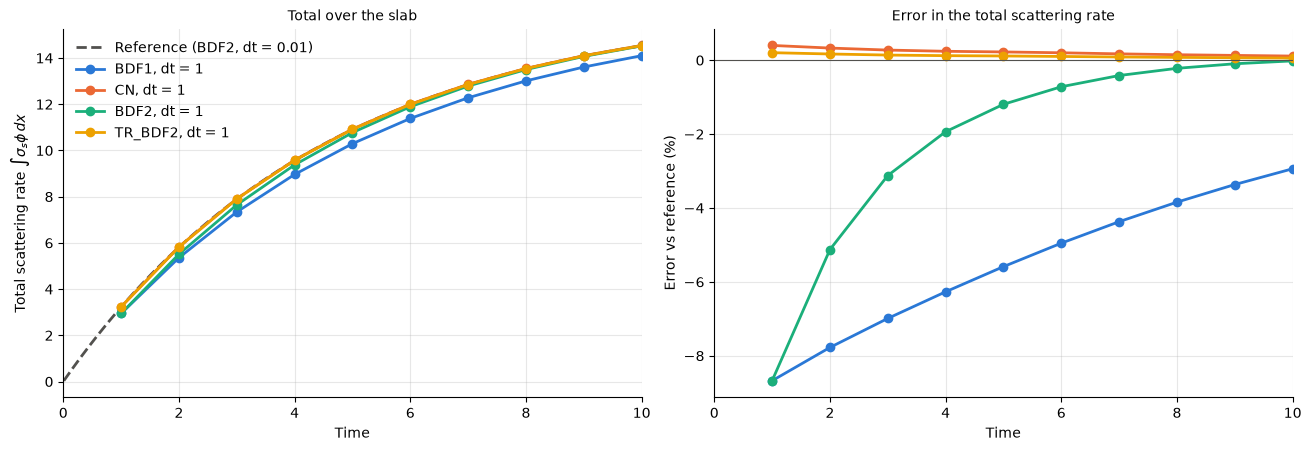

BDF1     largest error in total scattering rate: 8.68%
CN       largest error in total scattering rate: 0.40%
BDF2     largest error in total scattering rate: 8.68%
TR_BDF2  largest error in total scattering rate: 0.20%


In [4]:
def scattering_rate(flux, scatter, medium_map):
    """Scattering reaction rate density, sigma_s * phi, in each cell.

    scatter is indexed [material, group out, group in], so summing over the
    outgoing group gives the total scattering cross section of each group.
    flux has the cell axes first and groups last.
    """
    sigma_s = scatter.sum(axis=1)  # (materials, groups)
    return np.sum(sigma_s[medium_map] * flux, axis=-1)


delta_x = np.diff(edges_x)


def total_scattering(flux_history):
    rate = scattering_rate(flux_history, reed_materials.scatter, medium_map)
    return rate @ delta_x  # integrate over the slab at each step


ref_times, ref_flux = reference
ref_total = total_scattering(ref_flux)

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(13, 4.4), constrained_layout=True)
ax0.plot(ref_times, ref_total, label="Reference (BDF2, dt = 0.01)", **REFERENCE)
for color, (disc, (times, flux)) in zip(COLORS, coarse.items()):
    ax0.plot(times, total_scattering(flux), color=color, lw=2, marker="o", ms=6,
             label=f"{disc.name}, dt = 1")
ax0.set_xlabel("Time")
ax0.set_ylabel("Total scattering rate $\\int \\sigma_s \\phi \\, dx$")
ax0.set_title("Total over the slab", fontsize=10)
ax0.legend(frameon=False)

for color, (disc, (times, flux)) in zip(COLORS, coarse.items()):
    error = total_scattering(flux) / np.interp(times, ref_times, ref_total) - 1
    ax1.plot(times, 100 * error, color=color, lw=2, marker="o", ms=6, label=disc.name)
ax1.axhline(0.0, color="#52514e", lw=0.8)
ax1.set_xlabel("Time")
ax1.set_ylabel("Error vs reference (%)")
ax1.set_title("Error in the total scattering rate", fontsize=10)
for ax in (ax0, ax1):
    ax.set_xlim(0, 10)
    tidy(ax)
plt.show()

for disc, (times, flux) in coarse.items():
    error = total_scattering(flux) / np.interp(times, ref_times, ref_total) - 1
    print(f"{disc.name:8s} largest error in total scattering rate: "
          f"{100 * np.max(np.abs(error)):.2f}%")

The scattering regions have $v \sigma_t \Delta t = 1$, so they are not
stiff, and the oscillation in the source region (where $\sigma_s = 0$) has
little effect on them: CN and TR-BDF2 both stay within 0.4% of the reference.
BDF1's first-order error is the largest, about 9% low at the first step and
still 3% low at $t = 10$. BDF2 takes a BDF1 step to start, because it needs
two previous steps, so it begins with the same error but recovers within a
few steps.

In practice: TR-BDF2 is the safest default for stiff problems that need
second-order accuracy. CN is accurate when the time step resolves the fastest
time scale in the problem, but oscillates when it does not. BDF1 is the most
robust and the least accurate.